# Лабораторная 2. Классическая обработка изображений

Задание целиком: `labs/lab02/README.md` в репозитории курса.

Ноутбук один на обе части:
- **Часть 1** (после лекции 2): освещённость и шум по всем фото, гистограммы, коррекция яркости, сравнение фильтров;
- **Часть 2** (после лекции 3): выделение животного на фото, проверка маски по разметке, признаки формы.

Как работать:
1. В первой ячейке впишите свой номер варианта.
2. Заполняйте ячейки с пометкой `TODO` сверху вниз. Ячейки без `TODO` уже готовы, их менять не нужно.
3. Пока вы не дошли до части 2, её ячейки можно не трогать: Run All проходит через них без ошибок.
4. В конце выполните Run All с нуля, скачайте ноутбук и `results.zip`.

В Kaggle включите интернет: Settings → Internet → On.

## 0. Установка и загрузка данных

Ячейка определяет, где запущен ноутбук, находит или скачивает `get_data.py` из репозитория курса и загружает ваш вариант. Ничего в ней менять не нужно, кроме `VARIANT`.

In [1]:
VARIANT = 8  # TODO: ваш порядковый номер в списке группы, например 7
DATA_SOURCE = None  # запасной путь: папка с архивами variant_NN.zip

import inspect
import sys
import urllib.request
from pathlib import Path

assert isinstance(VARIANT, int) and 0 <= VARIANT <= 22, (
    "Впишите свой номер варианта: целое число от 1 до 22"
)
if VARIANT == 0:
    print("ВНИМАНИЕ: вариант 00 демонстрационный, работа на нём не засчитывается")

if "google.colab" in sys.modules:
    ENV, DATA_ROOT = "colab", Path("/content/data")
elif Path("/kaggle/working").exists():
    ENV, DATA_ROOT = "kaggle", Path("/kaggle/working/data")
elif Path("../../data/get_data.py").exists():
    # Ноутбук открыт прямо из клона репозитория курса: данные кладём в его папку data/
    ENV, DATA_ROOT = "local", Path("../../data").resolve()
else:
    # Локально: ноутбук лежит в cv-2026-familiya/lab02/, данные кладём в cv-2026-familiya/data/.
    # Эта папка указана в .gitignore, в репозиторий она не попадёт.
    ENV, DATA_ROOT = "local", Path("..").resolve() / "data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print("среда:", ENV, "| папка данных:", DATA_ROOT)

GET_DATA_URL = "https://raw.githubusercontent.com/ykvnkm/computer-vision-course/main/data/get_data.py"
course_copy = Path("../../data/get_data.py")
kaggle_copies = (
    sorted(Path("/kaggle/input").glob("**/get_data.py")) if ENV == "kaggle" else []
)
if course_copy.exists():
    script_dir = course_copy.resolve().parent
elif kaggle_copies:
    # Kaggle с подключённым датасетом-зеркалом курса: интернет не нужен
    script_dir = kaggle_copies[0].parent
    print("get_data.py из подключённого датасета:", kaggle_copies[0])
else:
    script_dir = DATA_ROOT
    if not (script_dir / "get_data.py").exists():
        try:
            urllib.request.urlretrieve(GET_DATA_URL, script_dir / "get_data.py")
        except Exception as e:
            raise RuntimeError(
                "Не удалось скачать get_data.py. В Kaggle включите Internet в Settings; "
                "в остальных случаях проверьте подключение к сети."
            ) from e
sys.path.insert(0, str(script_dir))
from get_data import ensure_variant

params = inspect.signature(ensure_variant).parameters
kwargs = {"dest": DATA_ROOT} if "dest" in params else {}
if DATA_SOURCE and "source" in params:
    kwargs["source"] = DATA_SOURCE
DATA_DIR = Path(ensure_variant(VARIANT, **kwargs))
print("данные варианта:", DATA_DIR)
print(sorted(p.name for p in DATA_DIR.iterdir()))

среда: local | папка данных: /home/kerty/Projects/cv-2026-kabakov/data
Вариант 08 уже на месте: /home/kerty/Projects/cv-2026-kabakov/data/variant_08
данные варианта: /home/kerty/Projects/cv-2026-kabakov/data/variant_08
['.get_data.json', 'README.md', 'annotations', 'images', 'labels.csv', 'variant.json']


In [2]:
import time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from skimage.metrics import structural_similarity
from skimage.restoration import estimate_sigma

IMG_DIR = DATA_DIR / "images"
TRIMAP_DIR = DATA_DIR / "annotations" / "trimaps"
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

labels = pd.read_csv(DATA_DIR / "labels.csv")
print(
    len(labels),
    "фото,",
    labels["breed"].nunique(),
    "породы:",
    ", ".join(labels["breed"].unique()),
)
print("OpenCV", cv2.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

799 фото, 4 породы: american_pit_bull_terrier, Maine_Coon, Ragdoll, staffordshire_bull_terrier
OpenCV 4.14.0 | numpy 2.5.4 | pandas 3.1.0


### Общие функции

Готовый код, менять не нужно.

- `load_rgb(filename)` читает фото через Pillow с `.convert("RGB")` (в датасете есть файлы в режимах `L`, `RGBA`, `P`, это вы видели в лабе 1) и уменьшает его так, чтобы длинная сторона стала 512 px. Одинаковый масштаб нужен, чтобы ядро 5×5 действовало на всех фото одинаково.
- `load_trimap(filename, shape)` читает trimap и приводит его к размеру фото через `cv2.INTER_NEAREST`: значения 1, 2, 3 не смешиваются.
- `show_grid(images, titles, ncols, path)` рисует картинки сеткой и, если указан `path`, сохраняет PNG.

In [3]:
MAX_SIDE = 512  # длинная сторона после уменьшения, px


def load_rgb(filename):
    """Фото как RGB uint8, длинная сторона MAX_SIDE."""
    with Image.open(IMG_DIR / filename) as im:
        rgb = np.asarray(im.convert("RGB"))
    h, w = rgb.shape[:2]
    scale = MAX_SIDE / max(h, w)
    size = (round(w * scale), round(h * scale))  # cv2.resize ждёт (ширина, высота)
    interp = cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR
    return cv2.resize(rgb, size, interpolation=interp)


def load_trimap(filename, shape):
    """Trimap того же размера, что фото: 1 = животное, 2 = фон, 3 = граница."""
    with Image.open(TRIMAP_DIR / (Path(filename).stem + ".png")) as im:
        tri = np.asarray(im)
    return cv2.resize(tri, (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST)


def show_grid(images, titles=None, ncols=4, path=None, size=3.0):
    """Картинки сеткой: RGB как есть, 2D-массивы в оттенках серого. path: куда сохранить PNG."""
    nrows = (len(images) + ncols - 1) // ncols
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(size * ncols, size * nrows), squeeze=False
    )
    for ax in axes.ravel():
        ax.axis("off")
    for i, img in enumerate(images):
        ax = axes.ravel()[i]
        img = np.asarray(img)
        if img.dtype == bool:
            img = img.astype(np.uint8)
        if img.ndim == 2:
            ax.imshow(img, cmap="gray", vmin=0, vmax=1 if img.max() <= 1 else 255)
        else:
            ax.imshow(img)
        if titles is not None:
            ax.set_title(titles[i], fontsize=9)
    plt.tight_layout()
    if path is not None:
        plt.savefig(path, dpi=100)
    plt.show()


example = load_rgb(labels["filename"].iloc[0])
print(labels["filename"].iloc[0], example.shape, example.dtype)

american_pit_bull_terrier_1.jpg (341, 512, 3) uint8


# Часть 1. Освещённость, шум, фильтры

Делается после лекции 2. Результат части: четыре числа по каждому фото, гистограммы, сравнение способов поправить тёмные фото и сравнение фильтров на зашумлённых фото. Из этой части дальше понадобится одна переменная `BEST_FILTER`.

## 1.1 Четыре числа по каждому фото

| Число | Что показывает | Как считать |
|---|---|---|
| `mean_L` | средняя яркость | среднее канала L из `cv2.COLOR_RGB2LAB` (в 8-битном OpenCV L идёт от 0 до 255) |
| `std_L` | контраст | стандартное отклонение того же канала |
| `noise_sigma` | оценка шума в единицах яркости | `estimate_sigma(gray)` из `skimage.restoration` |
| `sharpness` | резкость: у размытого кадра мало перепадов | дисперсия `cv2.Laplacian(gray, cv2.CV_64F)` |

Допишите функцию `image_stats`. Следующая ячейка готова: она пройдёт по всем фото и сохранит `results/part1_stats.csv`.

In [4]:
def image_stats(rgb):
    """Словарь {"mean_L", "std_L", "noise_sigma", "sharpness"} для одного кадра."""
    # TODO: L = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)[..., 0]
    L = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)[..., 0]
    # TODO: gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    # TODO: верните четыре числа как float, например "mean_L": float(L.mean())
    return {
        "mean_L": float(L.mean()),
        "std_L": float(L.std()),
        "noise_sigma": float(estimate_sigma(gray, channel_axis=None)),
        "sharpness": float(cv2.Laplacian(gray, cv2.CV_64F).var()),
    }

In [5]:
rows = []
for r in labels.itertuples():
    with Image.open(IMG_DIR / r.filename) as im:
        width, height = im.size  # исходный размер файла
    rows.append(
        {
            "filename": r.filename,
            "breed": r.breed,
            "species": r.species,
            "width": width,
            "height": height,
            **image_stats(load_rgb(r.filename)),
        }
    )
stats = pd.DataFrame(rows)
stats.to_csv(RESULTS / "part1_stats.csv", index=False, float_format="%.4f")
stats.describe().round(2)

,width,height,mean_L,std_L,noise_sigma,sharpness
count,799.00,799.00,799.00,799.00,799.00,799.00
mean,422.98,382.38,122.46,57.83,1.34,560.36
std,101.76,95.31,30.94,13.37,1.14,723.72
min,119.00,174.00,33.49,23.95,0.00,6.53
25%,333.00,333.00,102.90,49.33,0.57,124.84
50%,500.00,375.00,124.01,57.75,0.99,324.19
75%,500.00,500.00,141.00,66.38,1.62,669.44
max,1024.00,900.00,223.50,101.56,7.21,7285.78


In [6]:
# TODO: средние четырёх чисел по породам: stats.groupby("breed")[[...]].mean().round(2)
#       Какая порода темнее остальных? У какой ниже резкость?
breed_stats = stats.groupby("breed")[["mean_L", "sharpness"]].mean().round(2)
print(f"{breed_stats["mean_L"].idxmin() = }")
print(f"{breed_stats["sharpness"].idxmin() = }")

breed_stats["mean_L"].idxmin() = 'Maine_Coon'
breed_stats["sharpness"].idxmin() = 'Ragdoll'


## 1.2 Гистограммы

Нужен один рисунок `results/histograms.png`: распределение `mean_L` по всем фото и гистограммы каналов R, G, B самого тёмного и самого светлого фото. Рядом с гистограммами удобно показать сами фото.

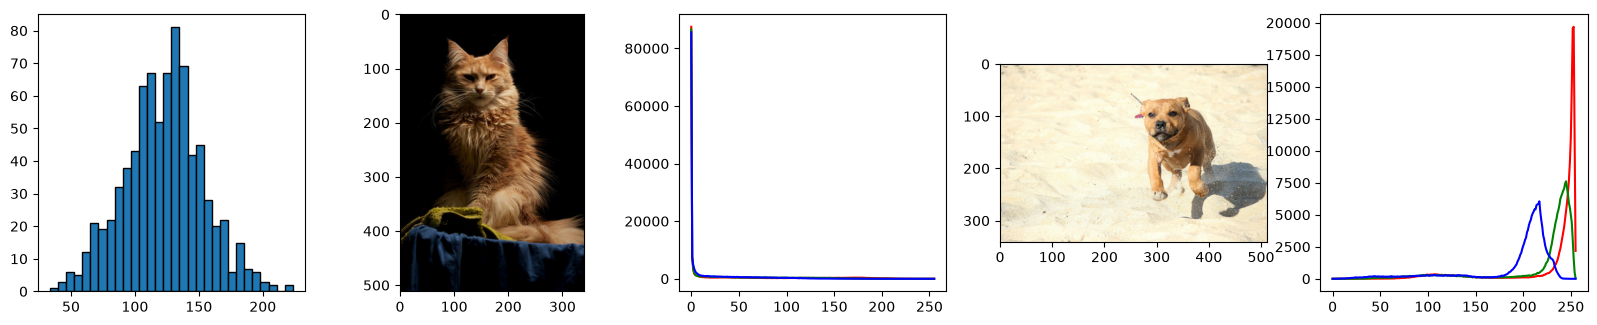

In [7]:
# TODO: самое тёмное и самое светлое фото: stats.loc[stats["mean_L"].idxmin(), "filename"] и idxmax()
# TODO: plt.subplots(1, 5, figsize=(20, 3.6)):
#       гистограмма stats["mean_L"] (bins=30), затем для каждого из двух фото само фото и гистограммы каналов.
#       Гистограмма канала c: np.bincount(rgb[..., c].ravel(), minlength=256) или cv2.calcHist
# TODO: plt.savefig(RESULTS / "histograms.png", dpi=100)

darkest = load_rgb(stats.loc[stats["mean_L"].idxmin(), "filename"])
brightest = load_rgb(stats.loc[stats["mean_L"].idxmax(), "filename"])

plt.figure(figsize=(20, 3.6))

plt.subplot(1, 5, 1)
plt.hist(stats["mean_L"], bins=30, edgecolor="black")

for i, image in enumerate((darkest, brightest)):
    plt.subplot(1, 5, 2 + 2 * i)
    plt.imshow(image)
    plt.subplot(1, 5, 3 + 2 * i)
    for c, color in enumerate(("red", "green", "blue")):
        hist = np.bincount(image[..., c].ravel(), minlength=256)
        plt.plot(hist, color=color)

plt.savefig(RESULTS / "histograms.png", dpi=100)

## 1.3 Освещённость

Возьмите 5 самых тёмных фото и сравните четыре способа их поправить:

| Метод | Что делает |
|---|---|
| `eq_rgb` | `cv2.equalizeHist` по каждому каналу R, G, B отдельно |
| `eq_L` | `cv2.equalizeHist` только по каналу L в Lab, каналы a и b не трогаем |
| `clahe_L` | CLAHE по каналу L: `cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))` |
| `gamma` | гамма-коррекция `255 * (x / 255) ** γ`; при γ < 1 тёмные места светлеют сильнее светлых |

Для каждого фото и метода нужны `mean_L` и `std_L` после коррекции и сдвиг цвета: насколько изменились каналы a и b в Lab. Функция `color_shift` готова.

In [8]:
def color_shift(before, after):
    """Средний сдвиг цвета |Δa| + |Δb| в Lab между двумя RGB-кадрами. 0 = оттенки не изменились."""
    lab0 = cv2.cvtColor(before, cv2.COLOR_RGB2LAB).astype(np.float32)
    lab1 = cv2.cvtColor(after, cv2.COLOR_RGB2LAB).astype(np.float32)
    return float(np.abs(lab1[..., 1:] - lab0[..., 1:]).sum(axis=2).mean())

In [9]:
GAMMA = 0.5  # можно подобрать своё значение


def correct(rgb, method):
    """method: "eq_rgb", "eq_L", "clahe_L" или "gamma". Возвращает RGB uint8 того же размера."""
    match method:
        # TODO: eq_rgb: cv2.split(rgb), equalizeHist для каждого канала, cv2.merge
        case "eq_rgb":
            rgb = cv2.merge([cv2.equalizeHist(ch) for ch in cv2.split(rgb)])
        # TODO: eq_L и clahe_L: L, a, b = cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)),
        #       обработать только L, собрать cv2.merge([L, a, b]) и вернуть через cv2.COLOR_LAB2RGB
        case "eq_L":
            L, a, b = cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))
            rgb = cv2.cvtColor(
                cv2.merge([cv2.equalizeHist(L), a, b]), cv2.COLOR_LAB2RGB
            )
        case "clahe_L":
            L, a, b = cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))
            clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
            rgb = cv2.cvtColor(cv2.merge([clahe.apply(L), a, b]), cv2.COLOR_LAB2RGB)
        # TODO: gamma: таблица lut из 256 значений 255 * (i / 255) ** GAMMA в uint8, затем cv2.LUT(rgb, lut)
        case "gamma":
            lut = np.array(
                [255 * (i / 255) ** GAMMA for i in range(256)], dtype=np.uint8
            )
            rgb = cv2.LUT(rgb, lut)
    return rgb

          mean_L  std_L  color_shift
method                              
clahe_L    60.57  60.76         0.36
eq_L      118.27  72.32         0.47
eq_rgb    122.58  73.92        14.68
gamma      88.12  55.14         4.87
original   41.73  50.28         0.00


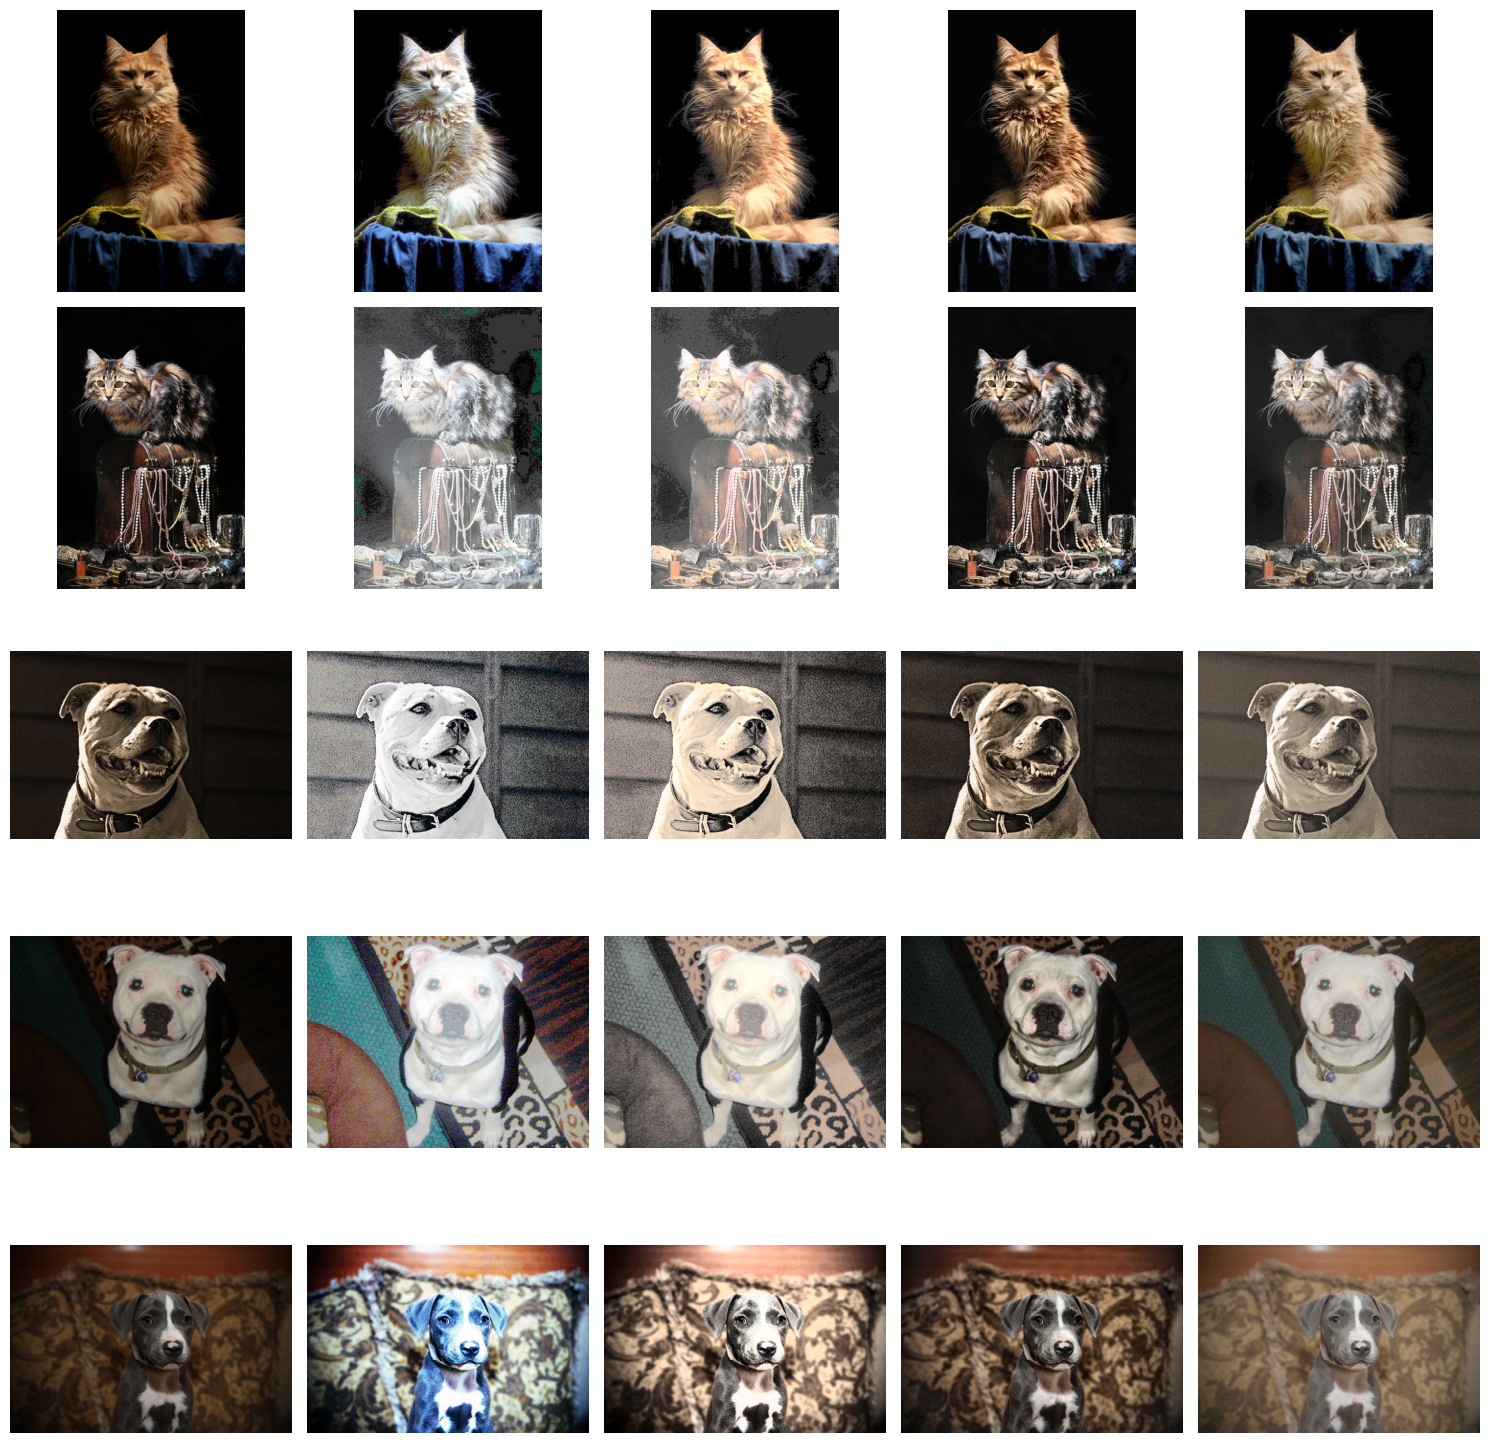

In [10]:
METHODS = ["eq_rgb", "eq_L", "clahe_L", "gamma"]

# TODO: 5 самых тёмных фото: stats.nsmallest(5, "mean_L")
darkest_5 = stats.nsmallest(5, "mean_L")

# TODO: таблица illum, строка на пару (фото, метод): filename, method, mean_L, std_L, color_shift.
#       Строки method="original" для исходных фото дают точку отсчёта.
#       Выведите средние по методам: illum.groupby("method")[["mean_L", "std_L", "color_shift"]].mean()
rows = []
for i, row in darkest_5.iterrows():
    filename = row["filename"]
    rgb = load_rgb(filename)
    rows.append(
        {
            "filename": filename,
            "method": "original",
            "mean_L": stats.loc[i, "mean_L"],
            "std_L": stats.loc[i, "std_L"],
            "color_shift": 0.0,
            "rgb": rgb,
        }
    )
    for method in METHODS:
        corrected = correct(rgb, method)
        corrected_stats = image_stats(corrected)
        rows.append(
            {
                "filename": filename,
                "method": method,
                "mean_L": corrected_stats["mean_L"],
                "std_L": corrected_stats["std_L"],
                "color_shift": color_shift(rgb, corrected),
                "rgb": corrected,
            }
        )

illum = pd.DataFrame(rows)
print(illum.groupby("method")[["mean_L", "std_L", "color_shift"]].mean().round(2))

# TODO: сетка 5 × 5 (исходное и 4 метода в строке): show_grid(..., ncols=5, path=RESULTS / "illumination.png")
show_grid(illum["rgb"], ncols=5, path=RESULTS / "illumination.png")


## 1.4 Свёртка руками

`cv2.blur(img, (3, 3))` усредняет каждый пиксель с восемью соседями. То же самое делает свёртка `cv2.filter2D` с ядром 3×3, в котором все девять чисел равны 1/9. Проверьте это на любом фото.

np.abs(filtered.astype(int) - blurred.astype(int)).max() = np.int64(0)
np.abs(filtered.astype(int) - sharpened.astype(int)).max() = np.int64(213)


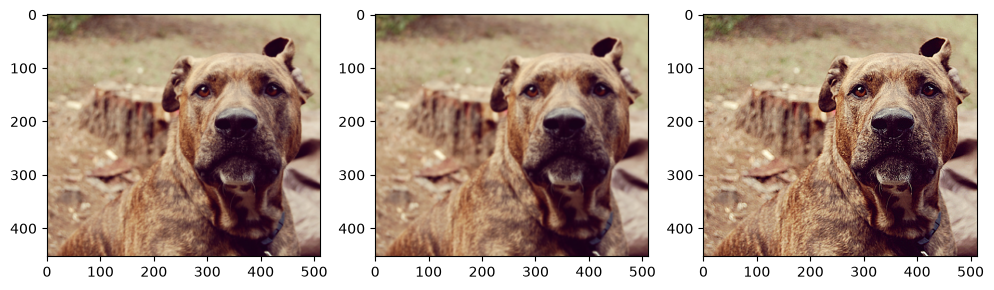

In [11]:
img = load_rgb(stats.sample()["filename"].item())

# TODO: kernel = np.ones((3, 3), np.float32) / 9
kernel = np.ones((3, 3), np.float32) / 9

# TODO: сравните cv2.filter2D(img, -1, kernel) и cv2.blur(img, (3, 3)); напечатайте максимум модуля разницы
#       (переведите оба результата в int перед вычитанием: в uint8 разность 3 - 5 даёт 254)
filtered = cv2.filter2D(img, -1, kernel)
blurred = cv2.blur(img, (3, 3))
print(f"{np.abs(filtered.astype(int) - blurred.astype(int)).max() = }")

# По желанию: ядро резкости [[0, -1, 0], [-1, 5, -1], [0, -1, 0]] и сравнение кропов до и после.
sharp_kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=np.float32)
sharpened = cv2.filter2D(img, -1, sharp_kernel)
print(f"{np.abs(filtered.astype(int) - sharpened.astype(int)).max() = }")

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(img)
plt.subplot(1, 3, 2)
plt.imshow(filtered)
plt.subplot(1, 3, 3)
plt.imshow(sharpened)
plt.show()

## 1.5 Шум и фильтры

У каждого варианта свой шум, он задан в `NOISE_PLAN`:

- `gauss`: к каждому пикселю добавлено случайное число из нормального распределения со стандартным отклонением `sigma` (в единицах яркости 0..255);
- `sp` («соль и перец»): доля `amount` пикселей стала чисто чёрной или чисто белой;
- `mix`: оба шума сразу.

Шум добавляется к 30 случайным фото варианта. Фильтр получает зашумлённое фото, результат сравнивается с исходным:

- PSNR в децибелах (`cv2.PSNR`): чем больше, тем ближе к исходному;
- SSIM от 0 до 1 (`structural_similarity`): похожесть по локальной структуре, ближе к тому, что видит глаз;
- время на кадр в миллисекундах.

Сравните `cv2.blur`, `cv2.GaussianBlur`, `cv2.medianBlur` с ядрами 3, 5, 7 и `cv2.bilateralFilter`. По желанию добавьте `cv2.fastNlMeansDenoisingColored`.

In [12]:
NOISE_PLAN = {
    0: {"kind": "gauss", "sigma": 20},
    1: {"kind": "sp", "amount": 0.05},
    2: {"kind": "mix", "sigma": 15, "amount": 0.03},
    3: {"kind": "gauss", "sigma": 30},
    4: {"kind": "sp", "amount": 0.10},
    5: {"kind": "mix", "sigma": 20, "amount": 0.05},
    6: {"kind": "gauss", "sigma": 10},
    7: {"kind": "sp", "amount": 0.02},
    8: {"kind": "mix", "sigma": 10, "amount": 0.02},
    9: {"kind": "gauss", "sigma": 25},
    10: {"kind": "sp", "amount": 0.08},
    11: {"kind": "mix", "sigma": 15, "amount": 0.05},
    12: {"kind": "gauss", "sigma": 15},
    13: {"kind": "sp", "amount": 0.04},
    14: {"kind": "mix", "sigma": 20, "amount": 0.03},
    15: {"kind": "gauss", "sigma": 30},
    16: {"kind": "sp", "amount": 0.06},
    17: {"kind": "mix", "sigma": 10, "amount": 0.04},
    18: {"kind": "gauss", "sigma": 20},
    19: {"kind": "sp", "amount": 0.03},
    20: {"kind": "mix", "sigma": 25, "amount": 0.05},
    21: {"kind": "gauss", "sigma": 25},
    22: {"kind": "sp", "amount": 0.10},
}


def add_noise(rgb, kind, sigma=0, amount=0.0, seed=0):
    """Зашумлённая копия RGB-кадра. kind: "gauss", "sp" или "mix"."""
    rng = np.random.default_rng(seed)
    out = rgb.astype(np.float32)
    if kind in ("gauss", "mix"):
        out = out + rng.normal(0, sigma, out.shape)
    out = np.clip(out, 0, 255).astype(np.uint8)
    if kind in ("sp", "mix"):
        r = rng.random(out.shape[:2])
        out[r < amount / 2] = 0
        out[r > 1 - amount / 2] = 255
    return out

шум варианта: kind=mix sigma=10 amount=0.02


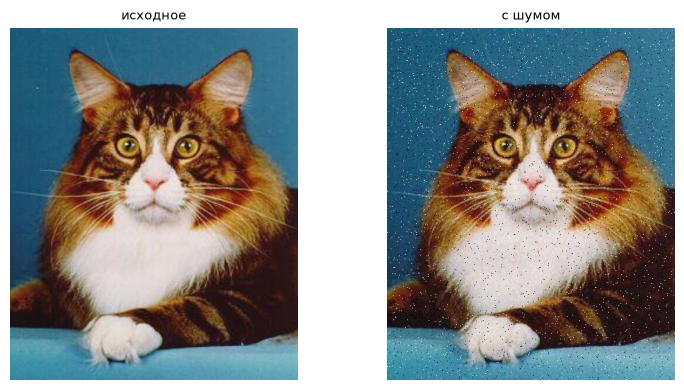

In [13]:
NOISE = NOISE_PLAN[VARIANT]
NOISE_NAME = " ".join(f"{k}={v}" for k, v in NOISE.items())
sample = labels.sample(30, random_state=VARIANT)
clean = [load_rgb(fn) for fn in sample["filename"]]
noisy = [add_noise(img, seed=VARIANT * 100 + i, **NOISE) for i, img in enumerate(clean)]
print("шум варианта:", NOISE_NAME)
show_grid([clean[0], noisy[0]], ["исходное", "с шумом"], ncols=2, size=4)

In [14]:
# TODO: словарь FILTERS: имя фильтра -> функция, которая принимает RGB uint8 и возвращает RGB uint8.
#       Нужны blur, GaussianBlur и medianBlur с ядрами 3, 5, 7 и bilateralFilter, например cv2.bilateralFilter(img, 9, 75, 75).
#       Пример записи: "median3": lambda img: cv2.medianBlur(img, 3)
FILTERS = {
    "blur3": lambda img: cv2.blur(img, (3, 3)),
    "blur5": lambda img: cv2.blur(img, (5, 5)),
    "blur7": lambda img: cv2.blur(img, (7, 7)),
    "gaussian3": lambda img: cv2.GaussianBlur(img, (3, 3), 0),
    "gaussian5": lambda img: cv2.GaussianBlur(img, (5, 5), 0),
    "gaussian7": lambda img: cv2.GaussianBlur(img, (7, 7), 0),
    "median3": lambda img: cv2.medianBlur(img, 3),
    "median5": lambda img: cv2.medianBlur(img, 5),
    "median7": lambda img: cv2.medianBlur(img, 7),
    "bilateral": lambda img: cv2.bilateralFilter(img, 9, 75, 75),
}

In [15]:
def quality(clean_img, out_img):
    """Насколько результат фильтра похож на чистый кадр: {"psnr": ..., "ssim": ...}."""
    # TODO: psnr через cv2.PSNR(clean_img, out_img)
    psnr = cv2.PSNR(clean_img, out_img)
    # TODO: ssim через structural_similarity(clean_img, out_img, channel_axis=2, data_range=255)
    ssim = structural_similarity(clean_img, out_img, channel_axis=2, data_range=255)
    return {"psnr": float(psnr), "ssim": float(ssim)}

In [16]:
# Готовый цикл: каждый фильтр на 30 фото, время и качество. "none" = зашумлённое фото без фильтра.
rows = []
for name, f in {"none": lambda img: img, **FILTERS}.items():
    for fn, c, n in zip(sample["filename"], clean, noisy):
        t0 = time.perf_counter()
        out = f(n)
        ms = (time.perf_counter() - t0) * 1000
        rows.append({"filter": name, "filename": fn, "ms": ms, **quality(c, out)})
filt = pd.DataFrame(rows)
filt_summary = filt.groupby("filter").mean(numeric_only=True).round(4)
filt_summary.insert(0, "noise", NOISE_NAME)
filt_summary.to_csv(RESULTS / "filters.csv")
filt_summary

,noise,ms,psnr,ssim
filter,,,,
bilateral,kind=mix sigma=10 amount=0.02,6.5186,21.5476,0.5679
blur3,kind=mix sigma=10 amount=0.02,0.2359,28.2892,0.7065
blur5,kind=mix sigma=10 amount=0.02,0.2733,28.3943,0.7399
blur7,kind=mix sigma=10 amount=0.02,0.3564,27.4529,0.7251
gaussian3,kind=mix sigma=10 amount=0.02,0.1914,28.0777,0.7003
gaussian5,kind=mix sigma=10 amount=0.02,0.2416,29.0291,0.7483
gaussian7,kind=mix sigma=10 amount=0.02,0.3480,29.0243,0.7704
median3,kind=mix sigma=10 amount=0.02,0.1395,31.9009,0.8355
median5,kind=mix sigma=10 amount=0.02,0.9024,30.7057,0.8280


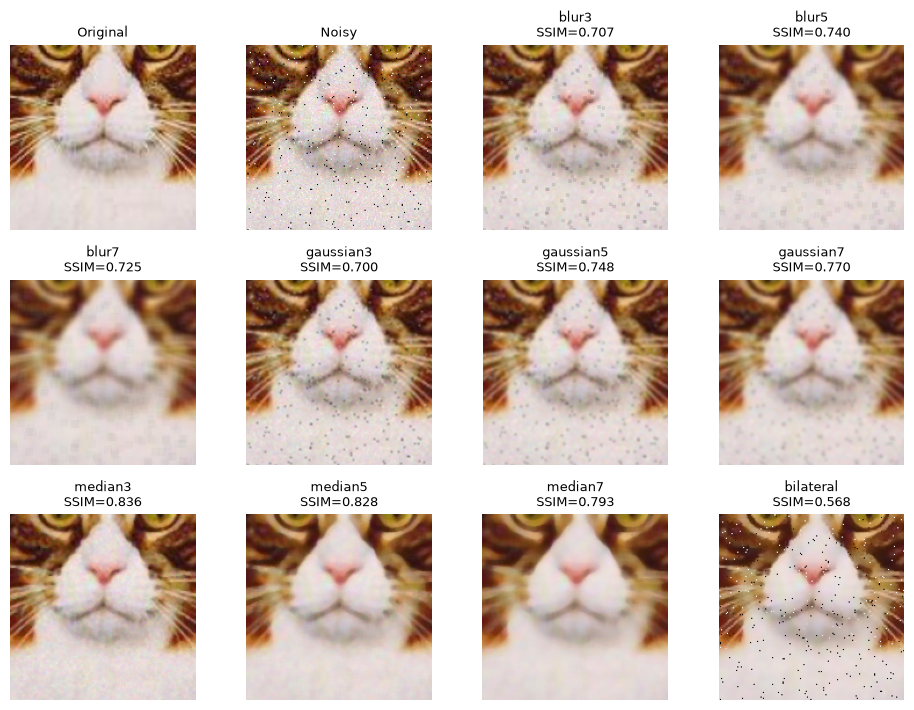

In [17]:
# TODO: кропы 160×160 из центра clean[0]: чистое, с шумом и после каждого фильтра из FILTERS.
#       В подписи удобно вписать SSIM фильтра из filt_summary.
#       show_grid(crops, titles, ncols=7, path=RESULTS / "filters.png", size=2.4)


def center_crop(img, size=160):
    h, w = img.shape[:2]
    y = (h - size) // 2
    x = (w - size) // 2
    return img[y : y + size, x : x + size]


crops = []
titles = []

# Исходное изображение
crops.append(center_crop(clean[0]))
titles.append("Original")

crops.append(center_crop(noisy[0]))
titles.append("Noisy")

# Результаты фильтрации
for name, f in FILTERS.items():
    out = f(noisy[0])
    crops.append(center_crop(out))
    ssim_value = filt_summary.loc[name, "ssim"]
    titles.append(f"{name}\nSSIM={ssim_value:.3f}")

# Визуализация
show_grid(crops, titles, ncols=4, path=RESULTS / "filters.png", size=2.4)

In [18]:
# TODO: выберите лучший фильтр по таблице filt_summary (метрики, время) и по кропам.
#       Отсортировать таблицу: filt_summary.sort_values("ssim", ascending=False)
BEST_FILTER = "median3"  # TODO: имя из FILTERS, например "median5"
filt_summary.sort_values("ssim", ascending=False)

,noise,ms,psnr,ssim
filter,,,,
median3,kind=mix sigma=10 amount=0.02,0.1395,31.9009,0.8355
median5,kind=mix sigma=10 amount=0.02,0.9024,30.7057,0.8280
median7,kind=mix sigma=10 amount=0.02,13.9829,29.3287,0.7932
gaussian7,kind=mix sigma=10 amount=0.02,0.3480,29.0243,0.7704
gaussian5,kind=mix sigma=10 amount=0.02,0.2416,29.0291,0.7483
blur5,kind=mix sigma=10 amount=0.02,0.2733,28.3943,0.7399
blur7,kind=mix sigma=10 amount=0.02,0.3564,27.4529,0.7251
blur3,kind=mix sigma=10 amount=0.02,0.2359,28.2892,0.7065
gaussian3,kind=mix sigma=10 amount=0.02,0.1914,28.0777,0.7003


**Почему выбран этот фильтр.** Медианный фильтр с ядром 3×3 (median3) победил одновременно по PSNR (31.9009) и SSIM (0.8355), поэтому оба показателя подтверждают его преимущество. Время обработки является наименьшим - всего 0.1325 мс на кадр. На кропах видно, что он эффективно убирает шум «соль и перец» и сохраняет края объектов и мелкую шерсть лучше, чем фильтры с большими ядрами.

# Часть 2 (после лекции 3). Выделение животного и признаки формы

Эту часть делайте после лекции 3. Кто хочет, может сделать её сразу: все функции и подсказки ниже.

Задача: получить маску животного без нейросети. Пайплайн: канал → порог Оцу → полярность → морфология → заливка дыр → самая большая связная компонента → контур и признаки формы. Качество маски проверяем по trimap через IoU, пиксели границы (значение 3) не учитываем.

Из части 1 сюда приходит только `BEST_FILTER`.

In [19]:
def iou_ignore(pred, trimap):
    """IoU маски pred с животным из trimap; пиксели границы (значение 3) не учитываются."""
    valid = trimap != 3
    gt = trimap == 1
    pred = np.asarray(pred) > 0
    inter = np.logical_and(pred, gt)[valid].sum()
    union = np.logical_or(pred, gt)[valid].sum()
    return float(inter / union) if union else float("nan")


def overlay(rgb, mask, color=(0, 255, 0), alpha=0.45):
    """Фото с маской, закрашенной полупрозрачным цветом."""
    out = rgb.copy()
    m = np.asarray(mask) > 0
    out[m] = ((1 - alpha) * out[m] + alpha * np.array(color)).astype(np.uint8)
    return out


# Каналы, из которых можно выбирать. Можно добавить свои.
CHANNELS = {
    "gray": lambda rgb: cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY),
    "S": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV))[1],
    "V": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV))[2],
    "L": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))[0],
    "a": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))[1],
    "b": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))[2],
}

## 2.1 Один кадр по шагам

Пройдите пайплайн на одном фото и сохраните `results/pipeline.png`: исходное фото, trimap, серое, Оцу, после исправления полярности, после морфологии, после заливки и выбора компоненты, контур на фото, адаптивный порог для сравнения. В подписях укажите IoU масок.

Каждый шаг удобно сразу оформить функцией: в 2.2 из них соберётся `segment`.

In [20]:
EXAMPLE = (
    labels["filename"].sample(1, random_state=VARIANT).iloc[0]
)  # можно заменить на любое фото варианта
rgb = load_rgb(EXAMPLE)
tri = load_trimap(EXAMPLE, rgb.shape)
print(EXAMPLE, rgb.shape, "значения trimap:", np.unique(tri))

Maine_Coon_2.jpg (512, 418, 3) значения trimap: [1 2 3]


t = 123.0


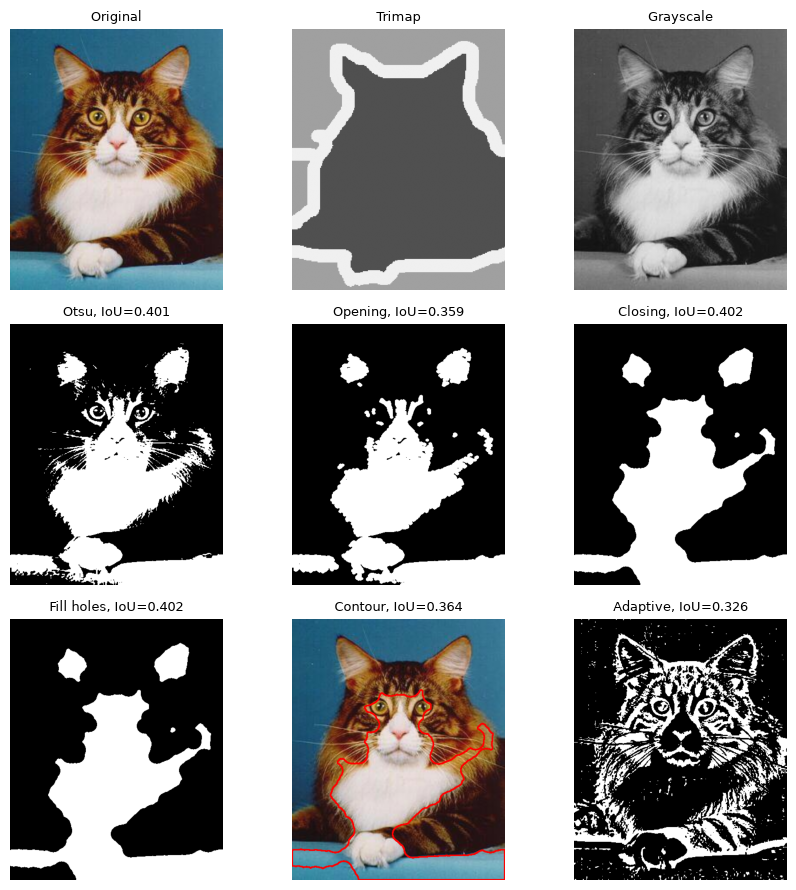

In [ ]:
# TODO: gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)


# TODO: Оцу: t, m = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU); напечатайте найденный порог t
def get_otsu(x):
    return cv2.threshold(x, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)


t, otsu = get_otsu(gray)
print(f"{t = }")


# TODO: полярность: если в рамке шириной 10 px по краям кадра больше половины пикселей белые,
#       белым стал фон: инвертируйте маску (cv2.bitwise_not)
def correct_polarity(mask):
    border = np.zeros(mask.shape, dtype=bool)
    border[:10, :] = True
    border[-10:, :] = True
    border[:, :10] = True
    border[:, -10:] = True

    if np.mean(mask[border] == 255) > 0.5:
        mask = cv2.bitwise_not(mask)

    return mask


otsu = correct_polarity(otsu)


# TODO: морфология: cv2.morphologyEx с cv2.MORPH_OPEN, затем cv2.MORPH_CLOSE,
#       ядро cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)); начните с k = 7 и k = 31
def morphology(mask, k_open=7, k_close=31):
    kernel_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_open, k_open))
    kernel_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_close, k_close))

    opened = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel_open)
    morph = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, kernel_close)

    return opened, morph


opened, morph = morphology(otsu)


# TODO: заливка дыр: cv2.copyMakeBorder на 1 px нулями, cv2.floodFill от угла (0, 0) другим цветом,
#       всё, до чего заливка не дошла, это объект вместе с его дырами
def fill_holes(mask):
    padded = cv2.copyMakeBorder(mask, 1, 1, 1, 1, cv2.BORDER_CONSTANT, value=0)
    flood = padded.copy()

    h, w = flood.shape
    flood_mask = np.zeros((h + 2, w + 2), np.uint8)
    cv2.floodFill(flood, flood_mask, (0, 0), 255)

    flood_inv = cv2.bitwise_not(flood)
    filled = cv2.bitwise_or(padded, flood_inv)

    return filled[1:-1, 1:-1]


filled = fill_holes(morph)


# TODO: самая большая компонента: cv2.connectedComponentsWithStats, столбец cv2.CC_STAT_AREA (метка 0 = фон)
def largest_component(mask):
    num_labels, labels_cc, stats_cc, centroids = cv2.connectedComponentsWithStats(
        mask, connectivity=8
    )

    if num_labels <= 1:
        return np.zeros_like(mask)

    areas = stats_cc[1:, cv2.CC_STAT_AREA]

    largest_label = 1 + np.argmax(areas)

    result = np.zeros_like(mask)
    result[labels_cc == largest_label] = 255

    return result


final_mask = largest_component(filled)

# TODO: контур: cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE), cv2.drawContours на копии rgb
contours, hierarchy = cv2.findContours(
    final_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE
)

contour_image = rgb.copy()

cv2.drawContours(contour_image, contours, -1, (255, 0, 0), 2)
# TODO: для сравнения cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 51, 5)
adaptive = cv2.adaptiveThreshold(
    gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 51, 5
)
adaptive = correct_polarity(adaptive)

# TODO: show_grid из 9 панелей (trimap покажите как tri * 80), подписи с iou_ignore(маска, tri),
#       path=RESULTS / "pipeline.png"
images = [rgb, tri * 80, gray, otsu, opened, morph, filled, contour_image, adaptive]
titles = [
    "Original",
    "Trimap",
    "Grayscale",
    f"Otsu, IoU={iou_ignore(otsu, tri):.3f}",
    f"Opening, IoU={iou_ignore(opened, tri):.3f}",
    f"Closing, IoU={iou_ignore(morph, tri):.3f}",
    f"Fill holes, IoU={iou_ignore(filled, tri):.3f}",
    f"Contour, IoU={iou_ignore(final_mask, tri):.3f}",
    f"Adaptive, IoU={iou_ignore(adaptive, tri):.3f}",
]

show_grid(images, titles, ncols=3, path=RESULTS / "pipeline.png", size=3)

## 2.2 Функция `segment` и выбор канала

`segment` повторяет шаги 2.1 для любого фото. Флаги включают шаги по одному: так в 2.3 будет видно, что даёт каждый. Пока функция не написана, она возвращает пустую маску, и ячейки ниже работают с IoU = 0.

Канал не обязан быть серым: животное может отличаться от фона насыщенностью (`S`) или цветом (`a`, `b`). Сравните минимум два канала из `CHANNELS` готовой функцией `evaluate` и выберите `CHANNEL`. Каждый вызов `evaluate` проходит по всем фото варианта и занимает 10–30 секунд.

In [ ]:
def segment(
    rgb,
    channel="gray",
    smooth=True,
    polarity=True,
    morph=True,
    fill=True,
    k_open=7,
    k_close=31,
):
    """Маска животного (bool, размер как у rgb)."""
    # TODO: smooth: если BEST_FILTER задан, rgb = FILTERS[BEST_FILTER](rgb)
    if smooth and BEST_FILTER is not None:
        rgb = FILTERS[BEST_FILTER](rgb)
    # TODO: канал x = CHANNELS[channel](rgb), затем Оцу
    x = CHANNELS[channel](rgb)
    _, mask = cv2.threshold(x, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # TODO: polarity, morph (с k_open и k_close), fill (заливка дыр и самая большая компонента),
    #       каждый шаг только при своём флаге

    if polarity:
        mask = correct_polarity(mask)

    if morph:
        _, mask = morphology(mask)

    if fill:
        mask = fill_holes(mask)
        mask = largest_component(mask)

    # TODO: верните mask > 0
    return mask > 0

In [23]:
def evaluate(configs):
    """configs: {имя: параметры segment}. Прогоняет segment на всех фото варианта.
    Возвращает таблицу IoU: строка = фото, столбец = имя набора параметров."""
    rows = []
    for fn in labels["filename"]:
        rgb = load_rgb(fn)
        tri = load_trimap(fn, rgb.shape)
        rows.append(
            {
                "filename": fn,
                **{
                    name: iou_ignore(segment(rgb, **kw), tri)
                    for name, kw in configs.items()
                },
            }
        )
    return pd.DataFrame(rows).set_index("filename")


def summarize(table):
    """Средняя и медианная IoU по каждому столбцу таблицы из evaluate."""
    return pd.DataFrame({"mean_iou": table.mean(), "median_iou": table.median()}).round(
        3
    )

In [24]:
# TODO: сравните минимум два канала, например:
#       ch = evaluate({"gray": dict(channel="gray"), "S": dict(channel="S")})
#       summarize(ch)
#       По желанию переберите размер ядра закрытия: {"k_close=15": dict(channel="gray", k_close=15), ...}
ch = evaluate(
    {
        "gray": {"channel": "gray"},
        "S": {"channel": "S"},
        "a": {"channel": "a"},
        "b": {"channel": "b"},
    }
)
summarize(ch)

,mean_iou,median_iou
gray,0.461,0.445
S,0.388,0.333
a,0.378,0.329
b,0.434,0.401


In [25]:
# TODO: впишите канал-победитель
CHANNEL = "gray"

## 2.3 Что даёт каждый шаг

Готовая ячейка: шаги включаются по одному на выбранном канале, результат сохраняется в `results/ablation.csv`.

In [26]:
ABLATION = {
    "1 только Оцу": {
        "channel": CHANNEL,
        "smooth": False,
        "polarity": False,
        "morph": False,
        "fill": False,
    },
    "2 + фильтр из части 1": {
        "channel": CHANNEL,
        "smooth": True,
        "polarity": False,
        "morph": False,
        "fill": False,
    },
    "3 + полярность": {
        "channel": CHANNEL,
        "smooth": True,
        "polarity": True,
        "morph": False,
        "fill": False,
    },
    "4 + морфология": {
        "channel": CHANNEL,
        "smooth": True,
        "polarity": True,
        "morph": True,
        "fill": False,
    },
    "5 + заливка и компонента": {
        "channel": CHANNEL,
        "smooth": True,
        "polarity": True,
        "morph": True,
        "fill": True,
    },
}
FINAL = ABLATION["5 + заливка и компонента"]

abl = evaluate(ABLATION)
abl_summary = summarize(abl)
abl_summary.to_csv(RESULTS / "ablation.csv", index_label="step")
print("канал:", CHANNEL, "| фильтр:", BEST_FILTER)
abl_summary

канал: gray | фильтр: median3


,mean_iou,median_iou
1 только Оцу,0.307,0.257
2 + фильтр из части 1,0.307,0.256
3 + полярность,0.410,0.395
4 + морфология,0.442,0.422
5 + заливка и компонента,0.461,0.445


## 2.4 Признаки формы

Для итоговой маски каждого фото нужны признаки самого большого внешнего контура:

| Признак | Как считать |
|---|---|
| `area_frac` | `cv2.contourArea(c)` / площадь кадра |
| `perimeter` | `cv2.arcLength(c, True)` |
| `x, y, w, h` | `cv2.boundingRect(c)` |
| `elongation` | длинная сторона / короткая сторона `cv2.minAreaRect(c)[1]` |
| `circularity` | 4π × площадь / периметр²; у круга 1, у вытянутой и рваной фигуры меньше |
| `solidity` | площадь / площадь `cv2.convexHull(c)`; лапы и хвост её уменьшают |

Допишите `shape_features`. Следующая ячейка готова: она соберёт `results/masks.csv` (строка на фото: IoU и признаки).

In [27]:
def shape_features(mask):
    """Признаки формы маски: area_frac, perimeter, x, y, w, h, elongation, circularity, solidity."""
    # TODO: contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    contours, _ = cv2.findContours(
        mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE
    )

    # TODO: если контуров нет, верните {}; иначе возьмите самый большой: max(contours, key=cv2.contourArea)
    if not contours:
        return {}
    c = max(contours, key=cv2.contourArea)

    # TODO: посчитайте признаки из таблицы выше; следите за делением на ноль
    x, y, w, h = cv2.boundingRect(c)
    area = cv2.contourArea(c)
    perimeter = cv2.arcLength(c, True)
    side1, side2 = cv2.minAreaRect(c)[1]
    hull_area = cv2.contourArea(cv2.convexHull(c))
    return {
        "area_frac": area / (mask.shape[0] * mask.shape[1]),
        "perimeter": perimeter,
        "x": x,
        "y": y,
        "w": w,
        "h": h,
        "elongation": max(side1, side2) / min(side1, side2)
        if min(side1, side2) > 0
        else 0.0,
        "circularity": 4 * np.pi * area / (perimeter**2) if perimeter > 0 else 0.0,
        "solidity": area / hull_area if hull_area > 0 else 0.0,
    }

In [28]:
rows = []
for r in labels.itertuples():
    rgb = load_rgb(r.filename)
    mask = segment(rgb, **FINAL)
    rows.append(
        {
            "filename": r.filename,
            "breed": r.breed,
            "species": r.species,
            "iou": iou_ignore(mask, load_trimap(r.filename, rgb.shape)),
            **shape_features(mask),
        }
    )
masks = pd.DataFrame(rows)
masks.to_csv(RESULTS / "masks.csv", index=False, float_format="%.4f")
masks.head()

,filename,breed,species,iou,area_frac,perimeter,x,y,w,h,elongation,circularity,solidity
0,american_pit_bull_terrier_1.jpg,american_pit_bull_terrier,dog,0.361799,0.255859,1262.856988,118,46,260,295,1.266547,0.351987,0.757200
1,american_pit_bull_terrier_2.jpg,american_pit_bull_terrier,dog,0.516645,0.378328,2029.332165,0,0,428,341,1.255882,0.201556,0.645866
2,american_pit_bull_terrier_3.jpg,american_pit_bull_terrier,dog,0.188598,0.550061,2543.439810,0,116,510,396,1.288608,0.279009,0.806704
3,american_pit_bull_terrier_4.jpg,american_pit_bull_terrier,dog,0.555755,0.332732,2892.507914,1,0,511,340,1.561787,0.086997,0.419352
4,american_pit_bull_terrier_5.jpg,american_pit_bull_terrier,dog,0.033711,0.234242,2134.559648,19,0,486,236,2.082562,0.167039,0.646850


In [29]:
# TODO: сводка по породам: masks.groupby("breed")[["iou", "area_frac", "elongation", "circularity", "solidity"]].mean()
#       На какой породе метод работает хуже всего? Отличаются ли кошки и собаки по форме маски?
breed_summary = (
    masks.groupby("breed")[
        ["iou", "area_frac", "elongation", "circularity", "solidity"]
    ]
    .mean()
    .round(3)
    .sort_values("iou")
)
display(breed_summary)

species_summary = (
    masks.groupby("species")[
        ["iou", "area_frac", "elongation", "circularity", "solidity"]
    ]
    .mean()
    .round(3)
)
display(species_summary)

,iou,area_frac,elongation,circularity,solidity
breed,,,,,
american_pit_bull_terrier,0.428,0.420,1.430,0.282,0.701
staffordshire_bull_terrier,0.435,0.432,1.466,0.284,0.712
Ragdoll,0.469,0.407,1.480,0.338,0.737
Maine_Coon,0.511,0.442,1.482,0.306,0.722


,iou,area_frac,elongation,circularity,solidity
species,,,,,
cat,0.490,0.424,1.481,0.322,0.730
dog,0.432,0.426,1.448,0.283,0.706


## 2.5 Лучшие и худшие маски

Галерея из 6 лучших и 6 худших масок по IoU сохраняется в `results/best_worst.png`. Посмотрите на худшие: что у них общего (фон того же цвета, что животное, тёмный кадр, ошибка в самой разметке)?

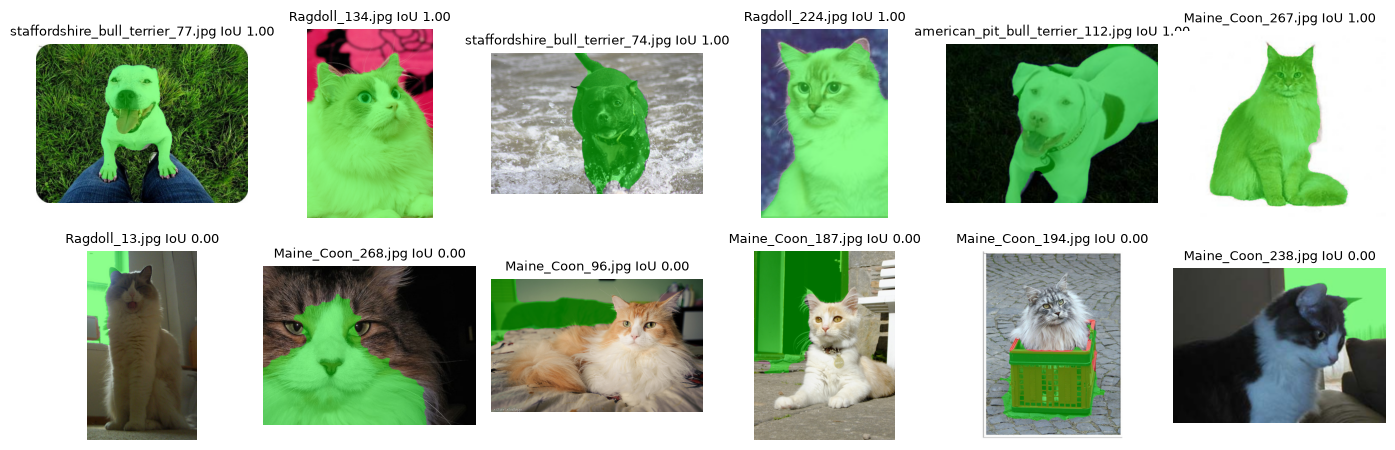

In [30]:
# TODO: ranked = masks.dropna(subset=["iou"]).sort_values("iou", ascending=False)
#       по 6 строк из начала и конца; для каждой: load_rgb, segment(rgb, **FINAL), overlay(rgb, mask)
#       подписи вида "Bengal_12.jpg IoU 0.91"
#       show_grid(panels, titles, ncols=6, path=RESULTS / "best_worst.png", size=2.3)
ranked = masks.dropna(subset=["iou"]).sort_values("iou", ascending=False)
best = ranked.head(6)
worst = ranked.tail(6)

panels = []
titles = []
for r in pd.concat([best, worst]).itertuples():
    rgb = load_rgb(r.filename)
    mask = segment(rgb, **FINAL)

    panels.append(overlay(rgb, mask))
    titles.append(f"{Path(r.filename).name} IoU {r.iou:.2f}")

show_grid(panels, titles, ncols=6, path=RESULTS / "best_worst.png", size=2.3)

## Выгрузка

Ячейка ниже проверяет, что все 9 файлов на месте, и печатает главное для отчёта. Затем упакуйте `results/` в архив и скачайте:
- в Kaggle: правая панель → Output → `results.zip` → Download; ноутбук: File → Download Notebook;
- в Colab: архив скачается сам после запуска ячейки; ноутбук: File → Download → Download .ipynb;
- локально: ничего скачивать не нужно, всё уже лежит в папке `lab02/`.

Переименуйте скачанный ноутбук в `solution.ipynb`.

In [31]:
print(
    f"вариант {VARIANT} | шум {NOISE_NAME} | BEST_FILTER = {BEST_FILTER} | CHANNEL = {CHANNEL}"
)

expected = {
    "part1_stats.csv",
    "histograms.png",
    "illumination.png",
    "filters.csv",
    "filters.png",
    "pipeline.png",
    "ablation.csv",
    "masks.csv",
    "best_worst.png",
}
missing = sorted(expected - {p.name for p in RESULTS.iterdir()})
print("не хватает:", ", ".join(missing) if missing else "ничего, все 9 файлов на месте")

вариант 8 | шум kind=mix sigma=10 amount=0.02 | BEST_FILTER = median3 | CHANNEL = gray
не хватает: ничего, все 9 файлов на месте


In [32]:
import shutil

if ENV != "local":
    archive = shutil.make_archive("results", "zip", RESULTS)
    print("архив:", archive)
    if ENV == "colab":
        from google.colab import files

        files.download(archive)